# <font color=5F9EA0> What factors most strongly influence NBA player salaries: <br> college background, team-level salary investment, or draft position?
</font>

**TEAM 2:** Alejandro Lopez, Luca Gillich, Milica Kurtovic, Sven Schaaser and Theodora Omiridou <br>

This analysis explores how NBA player salaries relate to college background, draft position, and team-level investment decisions.

### <mark style='background :beige' > Business Context and Motivation</mark>
The NBA is a multi-billion dollar industry where talent acquisition and salary allocation
directly impact team performance and financial sustainability. For team executives,
understanding which colleges produce the highest-earning players, which teams invest most
in talent, and whether draft position predicts career earnings are critical questions
that inform recruitment strategies and budget allocation.

<div style="background-color:#CBE9EB; border-left:5px solid #5F9EA0; padding:10px; border-radius:6px;">

Our project analyzes NBA player salaries from 2000-2025 to uncover data-driven insights
that can help:

**PROJECT GOALS:**
1. Identify which colleges produce the most successful (highest-paid) NBA players
2. Compare team salary spending strategies across the league
3. Determine if draft position predicts career earning potential
4. Provide actionable insights for talent scouts, team managers, and college programs

By joining player biographical data with salary information and team details, we can
answer strategic questions that would be impossible to address with isolated datasets.

We begin by importing the required Python libraries for data manipulation and visualization, followed by loading all datasets used in the analysis.

### <mark style='background :beige' > Import libraries and load data </mark>

In [ ]:
# import necessary libraries
import pandas as pd                                           # data loading, cleaning, and manipulation
import numpy as np                                            # numerical operations and calculations
import matplotlib.pyplot as plt                               # static data visualizations
import matplotlib.colors as mcolors                           # color handling, color palettes and normalization for plots
from matplotlib.offsetbox import OffsetImage, AnnotationBbox  # image annotations in plots
import seaborn as sns                                         # enhanced statistical visualizations
from PIL import Image                                         # image processing for logos and icons


In [ ]:
# load dataset into python using the pandas library we just imported in the cell above
data_salary = 'players_salary.csv'
players_stats = 'common_player_info.csv'
team_info = 'team_details.csv'

In [ ]:
# skip the first row (skiprows=1) since it's just the filename
player_df = pd.read_csv(players_stats, sep=',', on_bad_lines='skip', engine='python')
salary_df = pd.read_csv(data_salary, sep=',', on_bad_lines='skip', engine='python')
team_df = pd.read_csv(team_info, sep=',')

### <mark style='background :beige' > Data Inspection </mark>
Before cleaning and merging the datasets, we conduct an initial inspection to understand their structure, contents, and data quality.
This includes checking dataset size, column types, summary statistics, and potential data quality issues such as missing values or duplicates.


We first used simple exploratory functions such as `shape`, `info()`, `head()`, and `describe()` to check:

+ how many rows and columns the dataset contains

+ the data type of each column

+ the structure and cell content of each column

+ the descriptive statistics summary : whether there are extreme or unusual values that might affect the analysis

### <mark style='background :lightblue' > Dataset shape </mark>
We examine the number of rows and columns in each dataset to understand their size and scope before further analysis using `shape`.


In [ ]:
print("Player dataset shape:", player_df.shape)
print("Salary dataset shape:", salary_df.shape)
print("Team   dataset shape:", team_df.shape)

Player dataset shape: (1928, 33)
Salary dataset shape: (11327, 6)
Team   dataset shape: (25, 14)


### <mark style='background :lightblue' > Data Structure and Types </mark>
We inspect data types and non-null counts to identify potential issues such as missing values or incorrect variable types with the `info()` function.


In [ ]:
player_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1928 entries, 0 to 1927
Data columns (total 33 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   person_id                         1928 non-null   int64  
 1   first_name                        1928 non-null   object 
 2   last_name                         1928 non-null   object 
 3   display_first_last                1928 non-null   object 
 4   display_last_comma_first          1928 non-null   object 
 5   display_fi_last                   1928 non-null   object 
 6   player_slug                       1928 non-null   object 
 7   birthdate                         1928 non-null   object 
 8   school                            1915 non-null   object 
 9   country                           1928 non-null   object 
 10  last_affiliation                  1928 non-null   object 
 11  height                            1888 non-null   object 
 12  weight

In [ ]:
salary_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11327 entries, 0 to 11326
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   person_id   11327 non-null  int64  
 1   first_name  11327 non-null  object 
 2   last_name   11327 non-null  object 
 3   Salary      8861 non-null   float64
 4   Year        8861 non-null   float64
 5   Age         8861 non-null   float64
dtypes: float64(3), int64(1), object(2)
memory usage: 531.1+ KB


In [ ]:
team_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25 entries, 0 to 24
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   team_id             25 non-null     int64  
 1   abbreviation        25 non-null     object 
 2   nickname            25 non-null     object 
 3   yearfounded         25 non-null     float64
 4   city                25 non-null     object 
 5   arena               25 non-null     object 
 6   arenacapacity       16 non-null     float64
 7   owner               25 non-null     object 
 8   generalmanager      25 non-null     object 
 9   headcoach           24 non-null     object 
 10  dleagueaffiliation  25 non-null     object 
 11  facebook            25 non-null     object 
 12  instagram           25 non-null     object 
 13  twitter             25 non-null     object 
dtypes: float64(2), int64(1), object(11)
memory usage: 2.9+ KB


### <mark style='background :lightblue' > Preview of Data </mark>
We display the first five rows of each dataset to verify that the data loaded correctly and to gain an initial understanding of the variables. The `head()` function helps us do that.


In [ ]:
player_df.head()

,person_id,first_name,last_name,display_first_last,display_last_comma_first,display_fi_last,player_slug,birthdate,school,country,...,playercode,from_year,to_year,dleague_flag,nba_flag,games_played_flag,draft_year,draft_round,draft_number,greatest_75_flag
0,1505,Tariq,Abdul-Wahad,Tariq Abdul-Wahad,"Abdul-Wahad, Tariq",T. Abdul-Wahad,tariq-abdul-wahad,1974-11-03 00:00:00,San Jose State,France,...,tariq_abdul-wahad,1997.0,2003.0,N,Y,Y,1997,1,11,N
1,949,Shareef,Abdur-Rahim,Shareef Abdur-Rahim,"Abdur-Rahim, Shareef",S. Abdur-Rahim,shareef-abdur-rahim,1976-12-11 00:00:00,California,USA,...,shareef_abdur-rahim,1996.0,2007.0,N,Y,Y,1996,1,3,N
2,203518,Alex,Abrines,Alex Abrines,"Abrines, Alex",A. Abrines,alex-abrines,1993-08-01 00:00:00,FC Barcelona,Spain,...,alex_abrines,2016.0,2018.0,N,Y,Y,2013,2,32,N
3,1630173,Precious,Achiuwa,Precious Achiuwa,"Achiuwa, Precious",P. Achiuwa,precious-achiuwa,1999-09-19 00:00:00,Memphis,Nigeria,...,precious_achiuwa,2020.0,2023.0,N,Y,Y,2020,1,20,N
4,101165,Alex,Acker,Alex Acker,"Acker, Alex",A. Acker,alex-acker,1983-01-21 00:00:00,Pepperdine,USA,...,alex_acker,2005.0,2008.0,Y,Y,Y,2005,2,60,N


In [ ]:
salary_df.head()

,person_id,first_name,last_name,Salary,Year,Age
0,406,Shaquille,O'Neal,17142000.0,2000.0,27.0
1,406,Shaquille,O'Neal,19285000.0,2001.0,28.0
2,406,Shaquille,O'Neal,21428000.0,2002.0,29.0
3,406,Shaquille,O'Neal,23571000.0,2003.0,30.0
4,406,Shaquille,O'Neal,26571000.0,2004.0,31.0


In [ ]:
team_df.head()

,team_id,abbreviation,nickname,yearfounded,city,arena,arenacapacity,owner,generalmanager,headcoach,dleagueaffiliation,facebook,instagram,twitter
0,1610612737,ATL,Hawks,1949.0,Atlanta,State Farm Arena,18729.0,Tony Ressler,Travis Schlenk,Quin Snyder,College Park Skyhawks,https://www.facebook.com/hawks,https://instagram.com/atlhawks,https://twitter.com/ATLHawks
1,1610612741,CHI,Bulls,1966.0,Chicago,United Center,21711.0,Michael Reinsdorf,Arturas Karnisovas,Billy Donovan,Windy City Bulls,https://www.facebook.com/chicagobulls,https://instagram.com/chicagobulls,https://twitter.com/chicagobulls
2,1610612742,DAL,Mavericks,1980.0,Dallas,American Airlines Center,19200.0,Mark Cuban,Nico Harrison,Jason Kidd,Texas Legends,https://www.facebook.com/dallasmavs,https://instagram.com/dallasmavs,https://twitter.com/dallasmavs
3,1610612743,DEN,Nuggets,1976.0,Denver,Ball Arena,NaN,Stan Kroenke,Calvin Booth,Michael Malone,Grand Rapids Gold,https://www.facebook.com/DenverNuggets,https://instagram.com/nuggets,https://twitter.com/nuggets
4,1610612744,GSW,Warriors,1946.0,Golden State,Chase Center,NaN,Joe Lacob,Bob Myers,Steve Kerr,Santa Cruz Warriors,https://www.facebook.com/warriors,https://instagram.com/warriors,https://twitter.com/warriors


### <mark style='background :lightblue' > Summary Statistics </mark>
We compute summary statistics to understand the distribution, central tendencies, and variability of numerical features such as salaries and draft positions. This is done using the `describe()` function.


In [ ]:
pd.set_option('display.float_format', '{:,.0f}'.format)
player_df.describe()

,person_id,weight,team_id,from_year,to_year
count,"1,364","1,364","1,364","1,364","1,364"
mean,"635,793",221,"1,610,612,751","2,009","2,015"
std,"734,182",27,9,9,7
min,15,133,"1,610,612,737","1,983","2,001"
25%,"2,437",200,"1,610,612,744","2,002","2,009"
50%,"202,384",220,"1,610,612,751","2,011","2,017"
75%,"1,628,445",240,"1,610,612,759","2,017","2,023"
max,"1,631,323",330,"1,610,612,766","2,022","2,023"


In [ ]:
pd.set_option('display.float_format', '${:,.0f}'.format)
salary_df.describe()

,person_id,Salary,Year,Age
count,"$8,861","$8,861","$8,861","$8,861"
mean,"$463,858","$5,946,542","$2,014",$27
std,"$655,563","$7,703,256",$7,$4
min,$15,"$2,692","$2,000",$18
25%,"$2,224","$1,167,000","$2,008",$23
50%,"$201,587","$3,000,000","$2,014",$26
75%,"$203,961","$7,606,820","$2,020",$30
max,"$1,631,338","$55,761,216","$2,025",$42


In [ ]:
pd.set_option('display.float_format', '{:,.0f}'.format)
team_df.describe()

,team_id,yearfounded
count,25,25
mean,"1,610,612,753","1,970"
std,8,15
min,"1,610,612,737","1,946"
25%,"1,610,612,746","1,961"
50%,"1,610,612,754","1,970"
75%,"1,610,612,760","1,976"
max,"1,610,612,766","1,995"


### <mark style='background :lightgrey' > Drop irrelevant and redundant columns </mark>

We drop unnecessary columns (axis=1) using the `drop()` method to keep only the relevant features for our analysis.
This operation does not overwrite the original DataFrame but instead creates a new one.

In [ ]:
columns_to_drop_player = [
    'display_last_comma_first',
    'display_fi_last',
    'player_slug',
    'last_affiliation',
    'season_exp',
    'jersey',
    'rosterstatus',
    'games_played_current_season_flag',
    'playercode',
    'team_abbreviation',
    'team_code',
    'dleague_flag',
    'nba_flag',
    'games_played_flag',
    'greatest_75_flag',
    'team_city'
]

player_df = player_df.drop(columns=columns_to_drop_player)

player_df = player_df.dropna()

In [ ]:
salary_df = salary_df.dropna(subset=['Salary', 'Year'])

In [ ]:
columns_to_drop_team = [
    'facebook',
    'instagram',
    'twitter',
    'dleagueaffiliation',
    'generalmanager',
    'headcoach',
   'arenacapacity',
    'owner'
]

team_df = team_df.drop(columns=columns_to_drop_team)

### <mark style='background :beige' > Data Inspection </mark>
We check for missing values and duplicate entries to ensure the reliability of the analysis and to guide data cleaning decisions.


In [ ]:
player_df.isnull().sum()

person_id             0
first_name            0
last_name             0
display_first_last    0
birthdate             0
school                0
country               0
height                0
weight                0
position              0
team_id               0
team_name             0
from_year             0
to_year               0
draft_year            0
draft_round           0
draft_number          0
dtype: int64

In [ ]:
salary_df.isnull().sum()

person_id     0
first_name    0
last_name     0
Salary        0
Year          0
Age           0
dtype: int64

In [ ]:
team_df.isnull().sum()

team_id         0
abbreviation    0
nickname        0
yearfounded     0
city            0
arena           0
dtype: int64

### <mark style='background :lightgrey' > Dataset Shape After Cleaning </mark>

After removing irrelevant columns and handling missing values, we recheck dataset dimensions to confirm that the data is clean and ready for merging.


In [ ]:
print("Player dataset shape after cleaning:", player_df.shape)
print("Salary dataset shape after cleaning:", salary_df.shape)
print("Team   dataset shape after cleaning:", team_df.shape)

Player dataset shape after cleaning: (1364, 17)
Salary dataset shape after cleaning: (8861, 6)
Team   dataset shape after cleaning: (25, 6)


#### <mark style='background :lightblue' > Why multiple datasets are necessary </mark>
Using multiple datasets allows us to move beyond isolated statistics and instead examine how early career signals (college and draft position) interact with organizational decisions (team salary investment).

+ Each dataset contains different dimensions of information.
+ The salary dataset has earnings data but no context about player background or team details.
+ The player info has biographical data but no salary information.
+ The team details provide organizational context.

Only by combining these datasets can we answer our business questions about college pipelines, team spending strategies, and draft ROI.


### <mark style='background :beige' > Joining and Merging </mark>

To answer our research question, we perform three separate joins, each designed to address a specific business question. Each merged dataset supports a focused analysis linking player salaries to different explanatory factors.  

<div style="background-color:#CBE9EB; border-left:5px solid #5F9EA0; padding:10px; border-radius:6px;">
<b>Join 1: Which colleges produce the highest number of NBA players?</b>
</div>

+ Join player biographical data with salary information in order to check the players produced by each college.

In [ ]:
college_salary_df = player_df.merge(
    salary_df,
    on='person_id',
    how='inner')

In [ ]:
team_salary_df = player_df.merge(
    salary_df,
    on='person_id',
    how='inner')

final_df = team_salary_df.merge(
    team_df,
    on='team_id',
    how='left')

In [ ]:
college_total = college_salary_df.groupby('school')['Salary'].count()
top_10_total = college_total.sort_values(ascending=False).head(10)

print("Top 10 Colleges by Total NBA Players:")
print(top_10_total)

Top 10 Colleges by Total NBA Players:
school
Duke                   282
Kentucky               271
Kansas                 190
North Carolina         181
UCLA                   161
Florida                135
Connecticut            133
Arizona                133
Georgia Tech           112
Southern California    105
Name: Salary, dtype: int64


### <font color=5F9EA0>Insight — Join 1 (Colleges × Players)</font>


After joining player biographical data with salary information and **counting the number of players per college**, the **Top 3 universities by total number of NBA players** in our dataset are:

1. **DUKE — 282 players**  
2. **KENTUCKY — 271 players**  
3. **KANSAS — 190 players**

 This shows which colleges contribute the highest number of players to the NBA, identifying them as major talent pipelines for professional teams and scouts.

<div style="background-color:#CBE9EB; border-left:5px solid #5F9EA0; padding:10px; border-radius:6px;">
<b>Join 2: Which NBA teams have the highest average player salaries?</b>
</div>

+ Joining team information together with player and salary information to see what teams have the highest paid players.  

In [ ]:
team_avg = final_df.groupby('nickname')['Salary'].mean()
team_avg = team_avg.sort_values(ascending=False)


top_10 = team_avg.head(10)
print("Top 10 Teams by Average Player Salary:")
print(top_10.apply(lambda x: f"${x:,.0f}"))

Top 10 Teams by Average Player Salary:
nickname
Lakers          $8,720,304
Bucks           $8,529,590
Bulls           $8,398,956
76ers           $8,028,831
Heat            $8,018,924
Timberwolves    $7,804,066
Warriors        $7,610,964
Suns            $7,448,666
Nuggets         $6,617,234
Mavericks       $6,409,895
Name: Salary, dtype: object


### <font color=5F9EA0> Insight – Join 2 (Teams × Salaries) </font>

After joining team information with player and salary data and computing **average player salary per team**, we found that players on the following teams typically earn the most money:

1. **LAKERS $$8.720.304**
2. **BUCKS $8.529.590**
3. **BULLS $8.398.956**

This indicates that these teams generally pay higher salaries per player than most other franchises. Furthermore, this reflects team-level investment strategies rather than individual outliers.

<div style="background-color:#CBE9EB; border-left:5px solid #5F9EA0; padding:10px; border-radius:6px;">
<b>Join 3: How does a player’s draft position relate to their average salary?</b>
</div>

+ Joined the players draft information with their salaries to see the relationship between draft position and salary.

In [ ]:
draft_salary_df = player_df.merge(
    salary_df,
    on='person_id',
    how='inner'  )


In [ ]:
avg_salary_by_draft = (
    draft_salary_df.groupby('draft_number')['Salary']
      .mean()
      .reset_index()
      .rename(columns={'Salary': 'avg_salary'})
      .sort_values('draft_number')
)

avg_salary_by_draft_formatted = avg_salary_by_draft.copy()
avg_salary_by_draft_formatted['avg_salary'] = avg_salary_by_draft_formatted['avg_salary'].apply(lambda x: f"${x:,.0f}")
print(avg_salary_by_draft_formatted.head(10))

  draft_number   avg_salary
0            0   $2,245,618
1            1  $16,517,951
2           10   $5,929,766
3           11   $8,165,192
4           12   $6,122,151
5           13   $9,747,613
6           14   $5,332,467
7           15   $8,657,116
8           16   $6,087,264
9           17   $7,541,641


### <font color=5F9EA0> Insight — Join 3 (Draft Position × Salaries) </font>

By joining players’ draft information with their salaries and calculating the **average salary by draft position**, we explored the relationship between where a player is drafted and how much they earn.

The results indicate that **earlier draft picks tend to have higher average salaries than later picks.** .

This suggests that draft position is an important indicator of player value and earning potential — teams generally invest more in players selected earlier in the draft, as these players show more talent.


## <mark style='background :beige' > Exploratory Analysis and Visualizations </mark>

<div style="background-color:#CBE9EB; border-left:5px solid #5F9EA0; padding:10px; border-radius:6px;">
<b>How are NBA player salaries distributed across the league?</b>
</div>

Understanding the overall salary distribution provides important context for all subsequent analyses. It helps identify whether salaries are evenly distributed or concentrated among a small number of high-earning players.

Using the joined player–salary dataset `(college_salary_df)`, we visualize the distribution of player salaries with a histogram to assess skewness and the presence of extreme values.

#### <mark style='background :lightgrey'> 1) Visualization: Salary distribution in the NBA </mark>

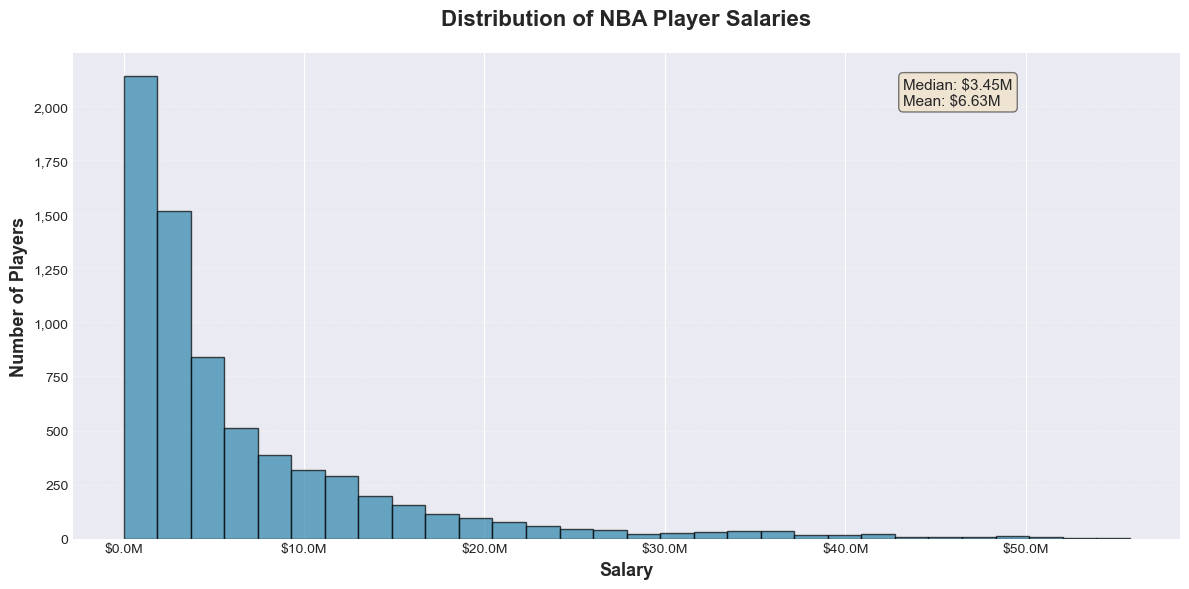

In [ ]:
# Set style for better-looking plots
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

# Create figure with better size
fig, ax = plt.subplots(figsize=(12, 6))

# Create histogram with better styling
ax.hist(college_salary_df['Salary'], bins=30, color='#2E86AB',
        edgecolor='black', alpha=0.7)

# Format y-axis to show thousands
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{int(x):,}'))

# Format x-axis to show millions
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x/1e6:.1f}M'))

# Labels and title with better fonts
ax.set_xlabel('Salary', fontsize=13, fontweight='bold')
ax.set_ylabel('Number of Players', fontsize=13, fontweight='bold')
ax.set_title('Distribution of NBA Player Salaries', fontsize=16, fontweight='bold', pad=20)

# Add grid for better readability
ax.grid(axis='y', alpha=0.3, linestyle='--')

# Add statistics box
median_salary = college_salary_df['Salary'].median()
mean_salary = college_salary_df['Salary'].mean()
textstr = f'Median: ${median_salary/1e6:.2f}M\nMean: ${mean_salary/1e6:.2f}M'
props = dict(boxstyle='round', facecolor='wheat', alpha=0.5)
ax.text(0.75, 0.95, textstr, transform=ax.transAxes, fontsize=11,
        verticalalignment='top', bbox=props)

plt.tight_layout()
plt.show()

**<u>Insights:<u>** <br>
The salary distribution is highly right-skewed. Most players earn relatively moderate salaries, while a small number of players earn exceptionally high amounts.

**<u>Why it matters:<u>** <br>
This skewed distribution indicates that NBA team payrolls and league-wide salary figures are heavily influenced by a small group of superstar players. As a result, averages alone can be misleading, and distributional analyses are essential for informed decision-making.

**<u>AI - use**: <br>
+ <font color=grey> _**prompt**_ </font>: "Plot NBA player salary distribution as a histogram with formatted axes, grid, and a statistics box showing mean and median." <br>
+ <font color=grey> _**answer**_ </font>: Use matplotlib + Seaborn darkgrid: create histogram with bins and color, format x-axis in millions and y-axis with commas, add labels/title, grid, and annotate mean/median in a stats box.
+ <font color=grey> _**learnt**_ </font>: Histograms with clear axis formatting and a small statistics box make distributions immediately interpretable and highlight central tendencies.

<div style="background-color:#CBE9EB; border-left:5px solid #5F9EA0; padding:10px; border-radius:6px;">
<b>Is there a relationship between a player’s draft position and their salary?</b>
</div>

Draft picks represent significant investment decisions for NBA teams. Understanding whether earlier draft positions lead to higher salaries helps evaluate how draft expectations translate into financial outcomes.

Using the draft–salary dataset `(draft_salary_df)`, we create a scatterplot of draft pick versus salary and add a trend line to highlight the overall relationship.

#### <mark style='background :lightgrey'> 2) Visualization: Draft position and player salary </mark>

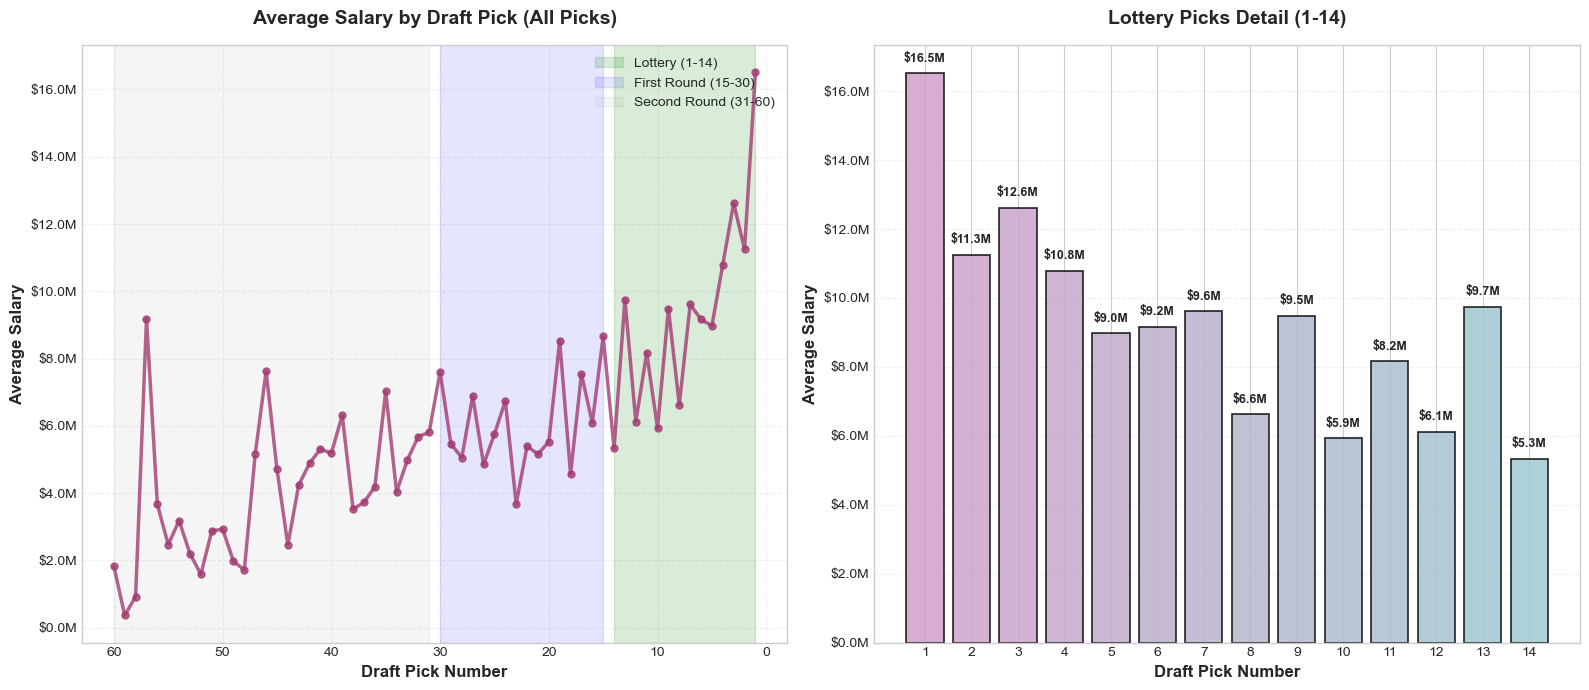

In [ ]:
# Set style
plt.style.use('seaborn-v0_8-whitegrid')

# Filter to only include valid draft picks (1-60) and remove undrafted
draft_salary_valid = draft_salary_df[
    (draft_salary_df['draft_number'].notna()) &
    (draft_salary_df['draft_number'] != '') &
    (draft_salary_df['draft_number'] != 'Undrafted')
].copy()

# Convert draft_number to numeric
draft_salary_valid['draft_number'] = pd.to_numeric(draft_salary_valid['draft_number'], errors='coerce')
draft_salary_valid = draft_salary_valid[(draft_salary_valid['draft_number'] >= 1) &
                                        (draft_salary_valid['draft_number'] <= 60)]

# Calculate average salary per draft pick
average_salary_by_draft_number = (
    draft_salary_valid
    .groupby('draft_number')['Salary']
    .mean()
)

# Create figure with two subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))

# --- Plot 1: Full draft range (1-60) - Line plot ---
ax1.plot(average_salary_by_draft_number.index,
         average_salary_by_draft_number.values,
         linewidth=2.5, color='#A23B72', marker='o',
         markersize=5, alpha=0.8)

# Format y-axis
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x/1e6:.1f}M'))

# Labels and title
ax1.set_xlabel('Draft Pick Number', fontsize=12, fontweight='bold')
ax1.set_ylabel('Average Salary', fontsize=12, fontweight='bold')
ax1.set_title('Average Salary by Draft Pick (All Picks)',
              fontsize=14, fontweight='bold', pad=15)

# Add shaded regions for different draft segments
ax1.axvspan(1, 14, alpha=0.15, color='green', label='Lottery (1-14)')
ax1.axvspan(15, 30, alpha=0.1, color='blue', label='First Round (15-30)')
ax1.axvspan(31, 60, alpha=0.08, color='gray', label='Second Round (31-60)')
ax1.legend(loc='upper right', fontsize=10)
ax1.grid(alpha=0.3, linestyle='--')
ax1.invert_xaxis()

# --- Plot 2: Lottery picks (1-14) - Bar chart with pink→teal gradient ---
lottery_data = average_salary_by_draft_number[average_salary_by_draft_number.index <= 14]

# Create a custom gradient colormap
cmap = mcolors.LinearSegmentedColormap.from_list("pink_teal", ['#D19FC9', '#9FC9D1'])
colors = [cmap(i / (len(lottery_data)-1)) for i in range(len(lottery_data))]

bars = ax2.bar(lottery_data.index, lottery_data.values,
               color=colors,
               edgecolor='black', linewidth=1.2, alpha=0.85)

# Format y-axis
ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x/1e6:.1f}M'))

# Labels and title
ax2.set_xlabel('Draft Pick Number', fontsize=12, fontweight='bold')
ax2.set_ylabel('Average Salary', fontsize=12, fontweight='bold')
ax2.set_title('Lottery Picks Detail (1-14)',
              fontsize=14, fontweight='bold', pad=15)

# Add value labels on bars
for pick, salary in lottery_data.items():
    height = salary
    ax2.text(pick, height + max(lottery_data.values)*0.02,
             f'${salary/1e6:.1f}M',
             ha='center', fontsize=9, fontweight='bold')

ax2.set_xticks(range(1, 15))
ax2.grid(axis='y', alpha=0.3, linestyle='--')

plt.tight_layout()
plt.show()


**<u>Insights:<u>** <br>
Earlier draft picks tend to be associated with higher salaries, but there is substantial variability. Several lower draft picks still achieve high salaries, indicating the presence of outliers and uncertainty.

**<u>Why it matters:<u>** <br>
While early draft picks generally offer higher expected financial returns, the wide dispersion highlights the risk involved in draft decisions. Teams must balance draft position with scouting, development, and long-term strategy.

**<u>AI - use**: <br>
+ <font color=grey> _**prompt**_ </font>: "Visualize average NBA salary by draft pick: full range (1–60) as a line plot with draft segments, and lottery picks (1–14) as a colored bar chart with gradient and labels." <br>
+ <font color=grey> _**answer**_ </font>: Use matplotlib with Seaborn whitegrid style: filter valid draft picks, compute average salary per pick, plot a line chart for all picks with shaded segments, and a gradient-colored bar chart for lottery picks with annotated salaries.
+ <font color=grey> _**learnt**_ </font>: Combining line plots for overall trends and gradient bars for key subsets effectively highlights patterns and emphasizes high-value segments.

<div style="background-color:#CBE9EB; border-left:5px solid #5F9EA0; padding:10px; border-radius:6px;">
<b>How does player salary differ across draft rounds?</b>
</div>

Comparing salary distributions across draft rounds helps assess whether early draft selections consistently outperform later ones in financial terms.

Using the same draft–salary dataset `(draft_salary_df)`, we visualize salary distributions by draft round with a boxplot to compare medians, variability, and outliers.

#### <mark style='background :lightgrey'> 3) Visualization: Salary differences by draft round</mark>

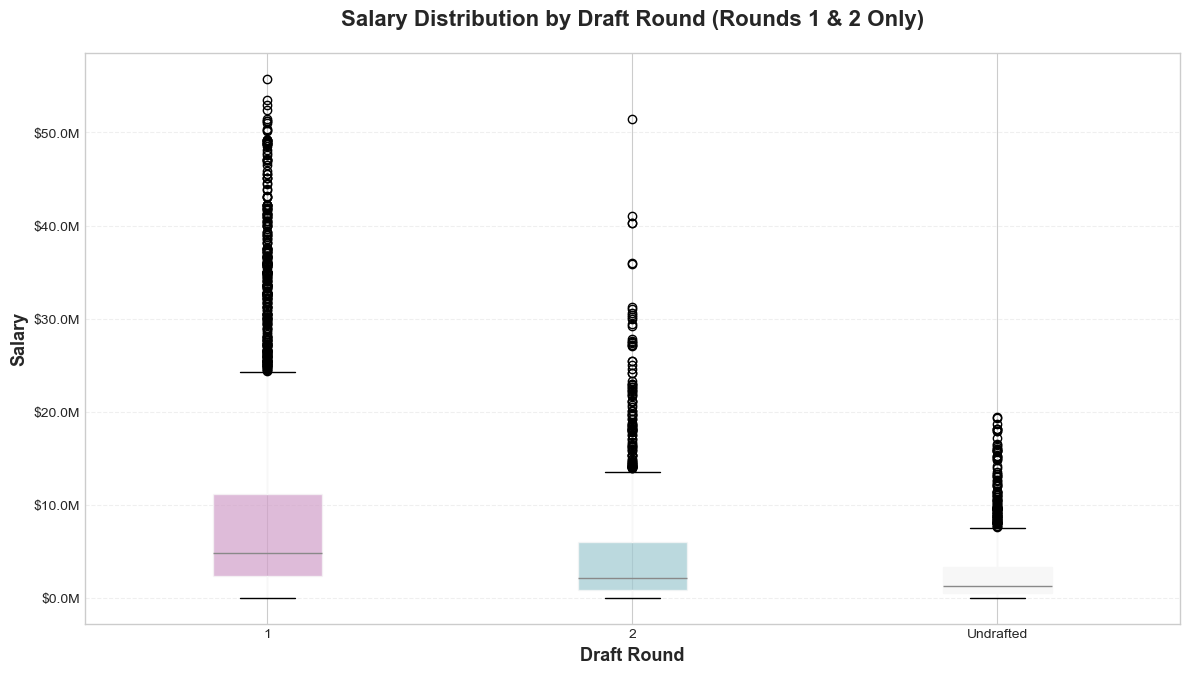

In [ ]:
# Set style
plt.style.use('seaborn-v0_8-whitegrid')

# Filter out draft_round == 0 (undrafted players) AND draft_round == 3
draft_salary_filtered = draft_salary_df[
    (draft_salary_df['draft_round'] != '0') &
    (draft_salary_df['draft_round'] != '3')
].copy()

# Create figure
fig, ax = plt.subplots(figsize=(12, 7))

# Create boxplot with better colors
bp = draft_salary_filtered.boxplot(column='Salary', by='draft_round', ax=ax,
                               patch_artist=True, return_type='dict')

# Color the boxes
colors = ['#D19FC9', '#9FC9D1']  # 2 colors for Round 1 and 2
for patch, color in zip(bp['Salary']['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

# Format y-axis
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x/1e6:.1f}M'))

# Labels and title
ax.set_xlabel('Draft Round', fontsize=13, fontweight='bold')
ax.set_ylabel('Salary', fontsize=13, fontweight='bold')
ax.set_title('Salary Distribution by Draft Round (Rounds 1 & 2 Only)',
             fontsize=16, fontweight='bold', pad=20)

# Remove the automatic title
plt.suptitle('')

# Grid
ax.grid(axis='y', alpha=0.3, linestyle='--')

plt.tight_layout()
plt.show()


**<u>Insights:<u>** <br>
First-round draft picks generally have higher median salaries, but there is significant overlap between rounds. Some later-round players earn salaries comparable to top first-round picks.

**<u>Why it matters:<u>** <br>
This suggests that while early draft rounds provide higher expected returns, later rounds can still produce high-value players. Effective talent development can therefore mitigate draft risk.

**<u>AI - use**: <br>
+ <font color=grey> _**prompt**_ </font>: "Show salary distribution for NBA Draft Rounds 1 & 2 using a colored boxplot, excluding undrafted and Round 3 players." <br>
+ <font color=grey> _**answer**_ </font>: Use matplotlib with Seaborn whitegrid style: filter draft data, plot a boxplot by draft round, color boxes differently for each round, format y-axis as dollars, and add labels and title.
+ <font color=grey> _**learnt**_ </font>: Boxplots with selective filtering and color coding make it easy to compare distributions across categories.

<div style="background-color:#CBE9EB; border-left:5px solid #5F9EA0; padding:10px; border-radius:6px;">
<b>Which universities have produced the highest-earning NBA players?</b>
</div>

Universities play a key role in player development. Identifying institutions linked to high total NBA salaries helps highlight strong talent pipelines.

Using the college–salary dataset `(college_salary_df)`, we aggregate player salaries by university and visualize the top institutions using a horizontal bar chart.

#### <mark style='background :lightgrey'> 4) Visualization: Universities Producing the Highest-Earning NBA Players </mark>

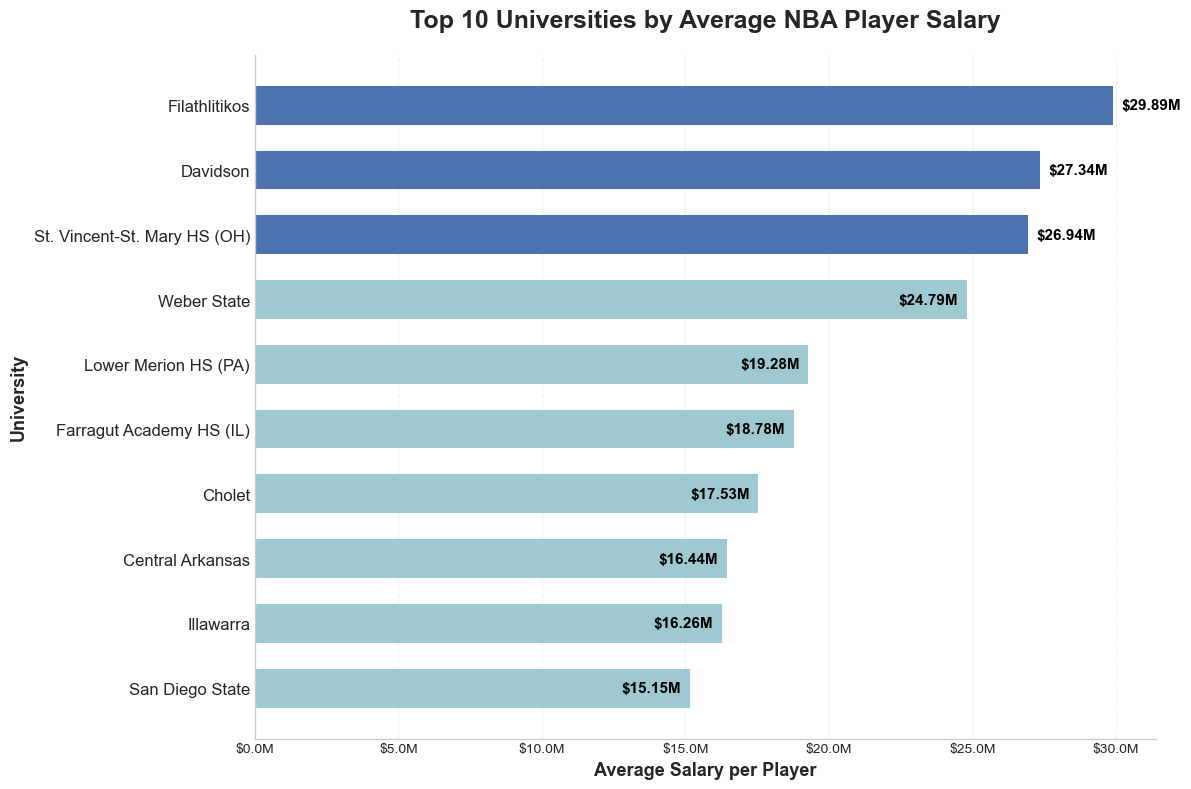

In [ ]:
# Use correct Seaborn whitegrid style
plt.style.use('seaborn-v0_8-whitegrid')

# --- Top colleges by average salary ---
top_colleges = (
    college_salary_df.groupby('school')['Salary']
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

fig, ax = plt.subplots(figsize=(12, 8))

# --- Colors: highlight top 3 with CBE9EB ---
colors = ['#4C72B0' if i < 3 else '#9FC9D1' for i in range(len(top_colleges))]

# Horizontal bars
bars = ax.barh(
    range(len(top_colleges)),
    top_colleges.values,
    color=colors,
    edgecolor='none',
    height=0.6
)

# --- Y-axis labels ---
ax.set_yticks(range(len(top_colleges)))
ax.set_yticklabels(top_colleges.index, fontsize=12)

# --- Format x-axis as dollars ---
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${x/1e6:.1f}M'))

# --- Invert y-axis so #1 is at the top ---
ax.invert_yaxis()

# --- Remove top/right spines for cleaner look ---
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# --- Add salary labels inside/outside bars ---
for i, (bar, value) in enumerate(zip(bars, top_colleges.values)):
    # Decide label alignment
    ha = 'left' if i < 3 else 'right'
    color = 'black'  # black works well on CBE9EB
    x_pos = value + max(top_colleges.values)*0.01 if i < 3 else value - max(top_colleges.values)*0.01
    ax.text(
        x_pos,
        i,
        f'${value/1e6:.2f}M',
        va='center',
        ha=ha,
        fontsize=11,
        fontweight='bold',
        color=color
    )

# --- Labels and title ---
ax.set_xlabel('Average Salary per Player', fontsize=13, fontweight='bold')
ax.set_ylabel('University', fontsize=13, fontweight='bold')
ax.set_title(
    'Top 10 Universities by Average NBA Player Salary',
    fontsize=18,
    fontweight='bold',
    pad=20
)

# --- Vertical grid lines only ---
ax.xaxis.grid(True, alpha=0.3, linestyle='--')
ax.yaxis.grid(False)

plt.tight_layout()
plt.show()


**<u>Insights:<u>** <br>
A small number of universities account for a disproportionately large share of total NBA salaries, indicating strong and consistent player development outcomes.

**<u>Why it matters:<u>** <br>
For agents this highlights institutions that consistently produce financially successful players, supporting more targeted talent identification strategies.

**<u>AI - use**: <br>
+ <font color=grey> _**prompt**_ </font>: "Plot top 10 universities by avg NBA player salary with horizontal bars, highlight top 3, and label salaries." <br>
+ <font color=grey> _**answer**_ </font>: Use matplotlib with Seaborn whitegrid style: compute top 10 college averages, plot horizontal bars, highlight top 3, invert y-axis, format x-axis as dollars, and annotate each bar with salary.
+ <font color=grey> _**learnt**_ </font>: Horizontal bar charts with color highlights and formatted labels make rankings and key contributors easy to interpret at a glance.

<div style="background-color:#CBE9EB; border-left:5px solid #5F9EA0; padding:10px; border-radius:6px;">
<b>Which NBA teams invest the most in player salaries on average?</b>
</div>

Team salary structures reflect strategic decisions around star players, depth, and risk management.

Using the team-level joined dataset `(final_df)`, we calculate the average player salary per team and rank the top teams.

#### <mark style='background :lightgrey'> 5) Visualization: Team Salary Investment </mark>

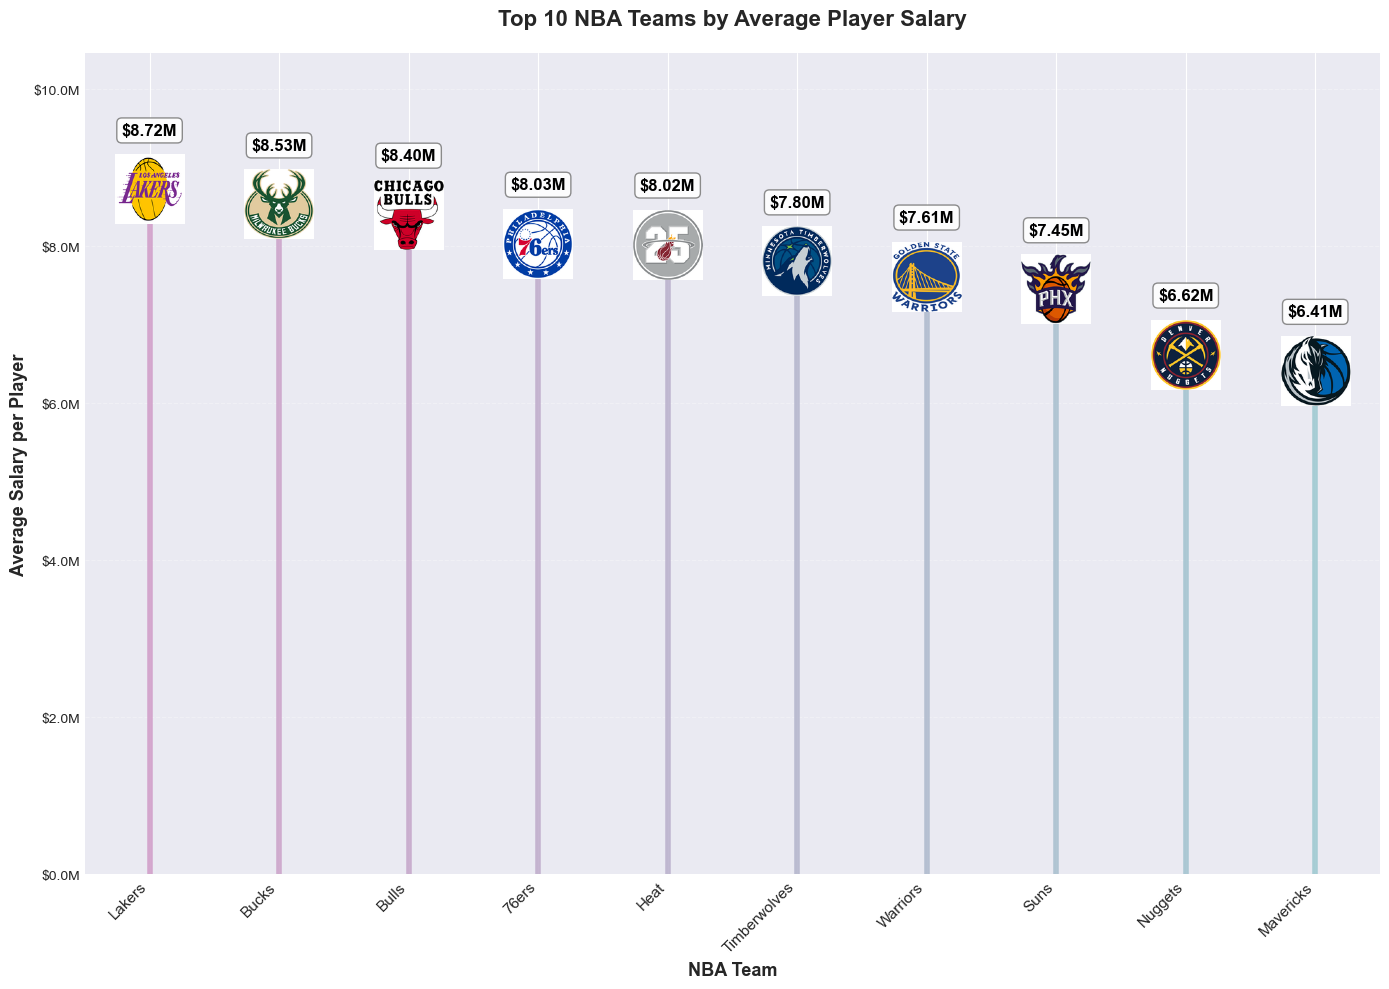

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
from PIL import Image
import matplotlib.colors as mcolors

# Set style
plt.style.use('seaborn-v0_8-darkgrid')

# Compute top 10 teams by average salary
team_avg_salary = (
    final_df.groupby('nickname')['Salary']
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

# Dictionary mapping team nicknames to logo filenames
logo_dict = {
    'Lakers': 'lakers.png',
    'Bucks': 'bucks.png',
    'Bulls': 'bulls.png',
    '76ers': '76ers.png',
    'Heat': 'heat.png',
    'Timberwolves': 'timberwolves.png',
    'Warriors': 'warriors.png',
    'Suns': 'suns.png',
    'Nuggets': 'nuggets.png',
    'Mavericks': 'mavericks.png'
}

# Create figure
fig, ax = plt.subplots(figsize=(14, 10))

# X positions
x = np.arange(len(team_avg_salary))

# --- Colors for lollipop sticks: pink→teal gradient ---
cmap = mcolors.LinearSegmentedColormap.from_list("pink_teal", ['#D19FC9', '#9FC9D1'])
colors = [cmap(i / (len(team_avg_salary)-1)) for i in range(len(team_avg_salary))]

# Target size for all logos (in pixels)
target_size = (100, 100)

# Plot lollipops
for i, (team, value, color) in enumerate(zip(team_avg_salary.index, team_avg_salary.values, colors)):

    # Draw the stem (lollipop stick)
    ax.plot([i, i], [0, value], color=color, linewidth=4, alpha=0.9, zorder=1)

    # Draw circle at the salary point
    ax.scatter(
        i, value,
        s=1100,
        color='white',
        edgecolor=color,
        linewidth=5,
        zorder=2
    )

    # Load and plot logo
    img = Image.open(logo_dict[team]).convert('RGBA')
    white_bg = Image.new('RGBA', img.size, (255, 255, 255, 255))
    final_img = Image.alpha_composite(white_bg, img).convert('RGB')
    img_resized = final_img.resize(target_size, Image.Resampling.LANCZOS)

    imagebox = OffsetImage(img_resized, zoom=0.5)
    ab = AnnotationBbox(
        imagebox,
        (i, value),
        frameon=False,
        box_alignment=(0.5, 0.5),
        zorder=5
    )
    ax.add_artist(ab)

    # Salary label above the logo
    ax.text(
        i,
        value + max(team_avg_salary.values) * 0.08,
        f'${value/1e6:.2f}M',
        ha='center',
        fontsize=12,
        fontweight='bold',
        color='black',
        zorder=6,
        bbox=dict(
            boxstyle='round,pad=0.3',
            facecolor='white',
            edgecolor='gray',
            alpha=0.9
        )
    )

# Format y-axis
ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, p: f'${x/1e6:.1f}M')
)

# Labels and title
ax.set_ylabel('Average Salary per Player', fontsize=13, fontweight='bold')
ax.set_xlabel('NBA Team', fontsize=13, fontweight='bold')
ax.set_title(
    'Top 10 NBA Teams by Average Player Salary',
    fontsize=16,
    fontweight='bold',
    pad=20
)

# Axis limits
ax.set_ylim(0, max(team_avg_salary.values) * 1.20)
ax.set_xlim(-0.5, len(team_avg_salary) - 0.5)

# X-ticks
ax.set_xticks(x)
ax.set_xticklabels(team_avg_salary.index, rotation=45, ha='right', fontsize=11)

# Grid
ax.grid(axis='y', alpha=0.3, linestyle='--')

plt.tight_layout()
plt.show()


**<u>Insights:<u>** <br>
Teams vary significantly in average player salary, suggesting different roster construction strategies, such as reliance on high-paid stars versus more evenly distributed payrolls.

**<u>Why it matters**: <br>
Understanding these salary strategies can inform benchmarking, contract negotiations, and long-term financial planning for teams operating under salary cap constraints.

**<u>AI - use**: <br>
+ <font color=grey> _**prompt**_ </font>: "Show top 10 NBA teams by avg player salary with logos and color gradients in a lollipop chart." <br>
+ <font color=grey> _**answer**_ </font>: Use matplotlib + PIL: compute top 10 salaries, plot sticks with a gradient, overlay logos via OffsetImage/AnnotationBbox, and add salary labels.
+ <font color=grey> _**learnt**_ </font>: Combining gradients, logos, and annotations in a chart makes complex data visually intuitive.

### <mark style='background:beige'>Key Insights and Business Implications</mark>

| **Category** | **Key Insights** | **Strategic Recommendations** |
|--------------|-----------------|-------------------------------|
| **Salary Spending** | A small group of star contracts drives a large share of total payroll, so “average salary” can hide real cost structure and risk. | Use distribution-based KPIs (median, percentiles, top-10% share) for payroll decisions instead of relying on averages. |
| **Draft Outcomes** | Early picks have higher expected payoffs, but value can emerge anywhere with the right development. | Treat draft selection like a risk portfolio: combine pick position with performance predictors (college/league stats, age, role fit) and scenario planning. |
| **Talent Pipelines** | Certain universities repeatedly produce top earners, suggesting some programs are reliable indicators of NBA readiness. | Invest in development to unlock surplus value: later-round picks can become high-return assets if supported by strong coaching, analytics, and minutes pathways. |
| **Team Payroll Strategies** | High-variance “star-heavy” approaches vs. more balanced rosters imply different risk/return profiles under cap constraints. | Benchmark roster construction: compare team payroll concentration and performance outcomes to identify which strategy is delivering better wins-per-dollar. |



### <mark style='background :beige' > AI usage disclosure & prompts </mark>
AI tools were used as a support for brainstorming, clarification, and code refinement, while all analytical decisions, interpretations, and final outputs were critically evaluated and validated by the team.